# Exploring Subreddits
Exploring what subreddits are available using PRAW and choosing a relevant subreddit for this study.

In [1]:
from dotenv import load_dotenv
import os

In [2]:
load_dotenv()

True

In [3]:
client_id = os.environ.get("REDDIT_CLIENT_ID")
client_secret = os.environ.get("REDDIT_CLIENT_SECRET")

In [4]:
import praw

client= praw.Reddit(
    client_id=client_id,
    client_secret=client_secret,
    user_agent="research/0.1"
)

## Exploring Subreddits
Found that r/resumes is a prominent subreddit

In [7]:
resume_subs = client.subreddits.search_by_name("resume")

for sub in resume_subs:
    print(f"r/{sub.display_name} - {sub.subscribers:,} subscribers")

r/Resume - 130,909 subscribers
r/resumes - 1,328,690 subscribers
r/ResumeExperts - 29,637 subscribers
r/ResumeTips - 18,217 subscribers
r/ResumeCoverLetterTips - 27,872 subscribers
r/resumesupport - 8,780 subscribers
r/resumesindia - 7,393 subscribers
r/resumeph - 16 subscribers
r/ResumeFairies - 7,083 subscribers
r/resumereview - 2,295 subscribers


## Downloading sample of r/resumes Posts
Retrieved all posts with >=1 comment over time period spanning January 1st, 2026 to November 1st, 2026.

In [8]:
import deepsift

In [9]:
from deepsift.scraper import RedditScraper
from deepsift.filters import Filters
from deepsift.models import PostField

filters = Filters(
    post_include_fields=[
        PostField.ID,
        PostField.TITLE,
        PostField.SELFTEXT,
        PostField.SCORE,
        PostField.NUM_COMMENTS,
        PostField.CREATED_UTC,
        PostField.SUBREDDIT,
        PostField.URL
    ],
    post_filter=lambda post: post.num_comments >= 1,
)

scraper = RedditScraper(
    filters=filters,
    post_workers=4,
    shard_days=30,
)

# uncomment to run extraction
# post_ids = scraper.scrape_posts(
#     subreddits=["resumes"],
#     from_dt="2026-01-01",
#     to_dt="2026-11-01",
#     output_path="data/subreddit_resumes_posts.parquet",
# )

# print(f"Scraped {len(post_ids)} curated posts.")

## Finding Relevant Posts in Retrieved Data

In [59]:
import pandas as pd

posts_path = "data/initial_eda/subreddit_resumes_posts.parquet"
posts = pd.read_parquet(posts_path)

In [2]:
posts.shape

(20827, 8)

In [3]:
# validating the time period was respected
posts["created_utc"] = pd.to_datetime(posts["created_utc"], unit="s")

In [4]:
# this validates that it we did get data for the complete time period requested
posts["created_utc"].describe()

count                         20827
mean     2026-05-14 14:14:26.002256
min             2026-01-01 00:29:21
25%      2026-02-25 15:13:13.500000
50%             2026-05-04 21:39:57
75%             2026-07-28 12:10:49
max             2026-10-31 22:55:34
Name: created_utc, dtype: object

In [5]:
# remove posts with empty selftext, as they are likely to be irrelevant posts
is_nonempty_text = posts["selftext"].str.strip().str.len() > 1
not_empty_posts = posts[is_nonempty_text]
not_empty_posts["selftext"].str.len().describe()

count    18801.000000
mean       345.065156
std        548.040952
min          4.000000
25%          9.000000
50%         54.000000
75%        519.000000
max      11280.000000
Name: selftext, dtype: float64

In [6]:
# checks posts with text less than 25% of the full dataset, as they may be irrelevant posts (found '[removed]' posts and '[deleted]' posts)
is_sufficient_length = not_empty_posts["selftext"].str.len() < not_empty_posts["selftext"].str.len().quantile(0.5)
is_valid_text = posts["selftext"].str.lower().isin(["[removed]", "[deleted]"]) == False
pd.DataFrame(not_empty_posts[is_sufficient_length]["selftext"].value_counts()).head(5)

,count
selftext,
[removed],9071
[deleted],79
Any feedback is appreciated!,3
Roast my resume,3
Looking for feedback on my resume,2


In [7]:
# filter out the rows to only valid posts with sufficient text length
sufficient_text_posts = posts[is_valid_text & is_nonempty_text]
sufficient_text_posts.shape

(9651, 8)

In [8]:
# filter out the duplicates
no_dups_sufficient_text_posts = sufficient_text_posts.drop_duplicates(subset=["selftext"])
no_dups_sufficient_text_posts.shape

(9501, 8)

In [9]:
# check url file types to see if there are any image attachments
endings = pd.DataFrame(no_dups_sufficient_text_posts["url"].str.split(".").str[-1].str.lower().value_counts())
likely_extensions = endings[endings.index.str.len() < 10]
likely_extensions.head(5)

,count
url,
jpeg,2108
png,1676
0,1
cv,1
pro/,1


In [10]:
# only keep posts with image attachments
has_attachment = no_dups_sufficient_text_posts["url"].str.split(".").str[-1].str.lower().isin(["jpeg", "png"])
valid_posts_w_attachments = no_dups_sufficient_text_posts[has_attachment]
valid_posts_w_attachments.shape

(3784, 8)

In [11]:
# only keep posts with a resume type in the title, which is usually in the format of [resume type]
pattern = r"\[(.*)\]"
valid_posts_w_attachments["resume_type"] = valid_posts_w_attachments["title"].str.extract(pattern)
valid_posts_w_attachments.shape

(3784, 9)

In [45]:
# actually parse the resume type from the title using regex
import re
import matplotlib.pyplot as plt

def extract_number(phrase) -> int | None:
    # if number exists in the phrase it returns it else None

    number_exists_pattern = ".*([0-9]+).*"
    number = re.search(number_exists_pattern, phrase)
    if number:
        return int(number.group(1))

    return None

def parse_exp_years(phrase) -> int | None:

    if "yoe" in phrase.lower() and len(phrase.strip().split()) <= 2:
        return extract_number(phrase)
    elif "years" in phrase.lower() and len(phrase.strip().split()) <= 2:
        return extract_number(phrase)
    elif "months" in phrase.lower() and len(phrase.strip().split()) <= 3:
        return extract_number(phrase) / 12 # divide by 12 to return year

    return None

def parse_country(phrase) -> str | None:
    # parses country if it exists in the phrase, else it returns None

    lower_bound, upper_bound = 0, 29 # determined from the length of the phrase
    if (lower_bound <= len(phrase) <= upper_bound):
        return phrase

    return None

def parse_current_role(phrase) -> str | None:
    # processes current role text

    return phrase.lower()

def parse_target_role(phrase) -> str | None:
    # processes target role text

    return phrase.lower()

def parse_resume_type(row):

    pattern = r"\[(.*)\]"
    match = re.search(pattern, row["title"])

    res: dict = {}

    if match:
        statement = match.group(1)

        # [X YoE, Current Role/Unemployed, Target Role, Country]
        res["relevant_part"] = statement

        # filter so only 4 parts exist
        parts = statement.split(",")
        if len(parts) != 4:
            return res

        # get years of experience
        years_exp = parse_exp_years(parts[0])
        if years_exp is not None:
            res["years_exp"] = years_exp

        # get current role
        current_role = parse_current_role(parts[1])
        if current_role is not None:
            res["current_role"] = current_role

        # get target role
        target_role = parse_target_role(parts[2])
        if target_role is not None:
            res["target_role"] = target_role

        # get country
        country = parse_country(parts[3])
        if country is not None:
            res["country"] = country

    return res

results = valid_posts_w_attachments.apply(parse_resume_type, axis=1, result_type="expand")
extracted = valid_posts_w_attachments.join(results)

### Verification

In [13]:
country_len = extracted["country"].str.len()
lower, upper = country_len.quantile(0.25), country_len.quantile(0.75)
iqr = upper - lower
lower_bound, upper_bound = lower - 1.5 * iqr, upper + 1.5 * iqr

In [14]:
country_len.describe()

count    3506.000000
mean        8.765545
std         4.729163
min         1.000000
25%         4.000000
50%         7.000000
75%        14.000000
max        29.000000
Name: country, dtype: float64

In [15]:
lower_bound

np.float64(-11.0)

In [16]:
upper_bound

np.float64(29.0)

In [17]:
extracted["current_role"].value_counts()

current_role
unemployed                       824
recent graduate                  184
student                          179
software engineer                 94
employed                          41
                                ... 
genai / ml engineering intern      1
adjuster/employed                  1
wilandland firefighter             1
data analyst co-op                 1
it business analyst intern         1
Name: count, Length: 1540, dtype: int64

In [18]:
# format of the relevant part: https://www.reddit.com/r/resumes/wiki/index/howtoparticipate/?screen_view_count=1
extracted[["relevant_part", "years_exp", "current_role", "target_role", "country", "url"]].dropna()

,relevant_part,years_exp,current_role,target_role,country,url
4,"3 YoE, Art Director/Laid Off, 2D artist/concep...",3.0,art director/laid off,2d artist/concept artist,Remote/USA,https://i.redd.it/83sxfzzyjzmh1.png
7,"5 YoE, Cyber Security Engineer, Cyber Security...",5.0,cyber security engineer,cyber security professional,United States,https://i.redd.it/nbf46vpagzmh1.png
14,"3 YoE, Enterprise Technology Consultant, Techn...",3.0,enterprise technology consultant,technology transformation consultant,United States,https://i.redd.it/l520cpuicymh1.jpeg
16,"11 YoE, Customer Service Rep, Content Moderati...",1.0,customer service rep,content moderation,USA,https://i.redd.it/iwq1hj0d5ymh1.png
17,"0 years, Student, Software Engineer Intern, India",0.0,student,software engineer intern,India,https://i.redd.it/6imdjs1j3ymh1.png
...,...,...,...,...,...,...
20797,"3 YoE, Undergraduate, Entry level in ESG or M...",3.0,undergraduate,entry level in esg or market analyst,Europe,https://i.redd.it/a3yatkx7zhbg1.jpeg
20804,"0 YOE, Data Analyst Co-op, Data Science Co-op,...",0.0,data analyst co-op,data science co-op,Canada,https://i.redd.it/7j0oeidtvgbg1.png
20809,"3 years, intern, intern, USA",3.0,intern,intern,USA,https://i.redd.it/uiworsxzkgbg1.jpeg
20817,"7 YOE, Employed, System Administrator/Cloud Ad...",7.0,employed,system administrator/cloud administrator,USA,https://i.redd.it/uzffeoknwfbg1.png


<Axes: ylabel='Frequency'>

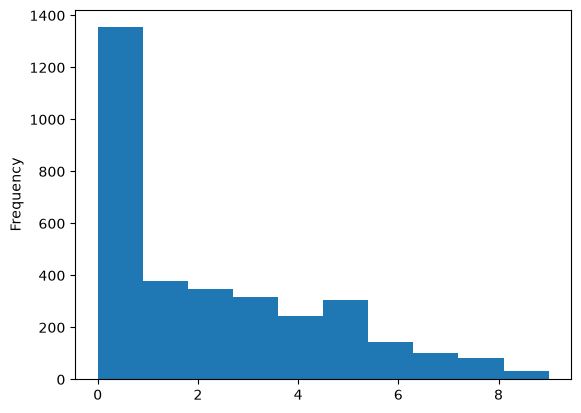

In [19]:
results["years_exp"].plot.hist()

### Cluster current role and target role columns

In [56]:
all_roles = pd.concat([extracted["current_role"], extracted["target_role"]]).dropna().str.strip()

In [58]:
all_roles.to_csv("unique_roles_sample_100.csv", index=False)

In [31]:
# clustering embeddings
from sklearn.cluster import AgglomerativeClustering

clustering = AgglomerativeClustering(
    n_clusters=None,
    distance_threshold=0.35,  # Adjust lower (0.2) for tighter groups, higher (0.4) for broader groups
    metric="cosine",
    linkage="average",
)
labels = clustering.fit_predict(embeddings)

In [32]:
unique_df = pd.DataFrame({"role": all_roles, "cluster": labels})

In [33]:
unique_df["cluster"].nunique()

400

In [39]:
unique_df[unique_df["cluster"] == 7]

,role,cluster
123,deli clerk,7
151,bakery clerk,7
152,retail clerk,7
246,retail merchandiser,7
365,freelance merchandiser,7
778,personal shopper,7
836,medical records clerk,7
1504,store clerk,7
1980,grocery clerk,7
2078,entry level bookseller,7


#### Evaluating Cluster Parameters

Running comparison sweep...

============================== COMPLETE LINKAGE ==============================
 threshold  clusters  silhouette  singleton_pct  largest_cluster_pct
      0.20      1618       0.198           55.7                  1.0
      0.25      1192       0.205           45.4                  1.4
      0.30       846       0.195           36.3                  2.1
      0.35       636       0.193           30.3                  3.7
      0.40       456       0.200           23.9                  6.2
      0.45       328       0.206           19.8                  6.5
      0.50       223       0.200           14.3                  6.5
      0.55       140       0.186           12.9                  9.2
      0.60        85       0.148            9.4                 10.9

============================== AVERAGE LINKAGE ==============================
 threshold  clusters  silhouette  singleton_pct  largest_cluster_pct
      0.20      1348       0.183           63.3       

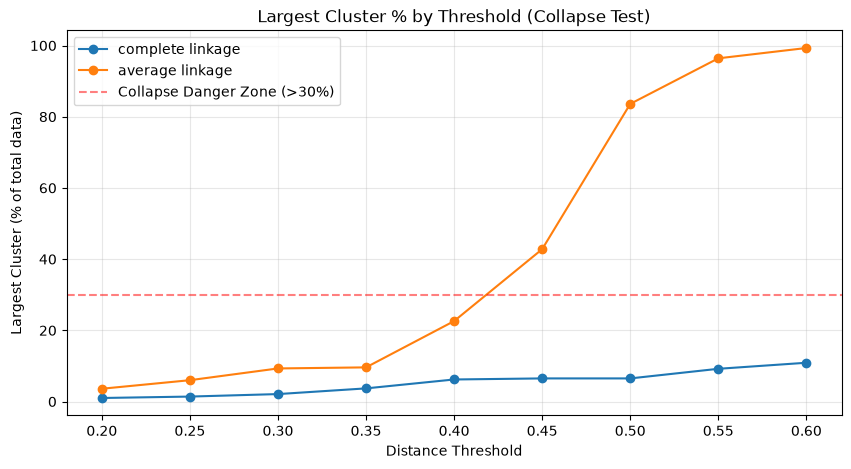

In [40]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

thresholds = np.arange(0.20, 0.65, 0.05)
linkages = ["complete", "average"]
results = []

print("Running comparison sweep...")

for linkage in linkages:
    for t in thresholds:
        clustering = AgglomerativeClustering(
            n_clusters=None, distance_threshold=t, metric="cosine", linkage=linkage
        )
        labels = clustering.fit_predict(embeddings)
        n_clusters = len(set(labels))

        # Silhouette score requires at least 2 clusters and less than N-1 clusters
        score = None
        if 1 < n_clusters < len(embeddings) - 1:
            score = round(
                silhouette_score(embeddings, labels, metric="cosine"), 3
            )

        counts = pd.Series(labels).value_counts()
        singleton_pct = round((counts == 1).sum() / len(counts) * 100, 1)
        largest_cluster_pct = round(counts.iloc[0] / len(embeddings) * 100, 1)

        results.append(
            {
                "linkage": linkage,
                "threshold": round(t, 2),
                "clusters": n_clusters,
                "silhouette": score,
                "singleton_pct": singleton_pct,
                "largest_cluster_pct": largest_cluster_pct,
            }
        )

df_results = pd.DataFrame(results)

# 1. Print Side-by-Side Tables
print("\n" + "=" * 30 + " COMPLETE LINKAGE " + "=" * 30)
print(
    df_results[df_results["linkage"] == "complete"]
    .drop(columns="linkage")
    .to_string(index=False)
)

print("\n" + "=" * 30 + " AVERAGE LINKAGE " + "=" * 30)
print(
    df_results[df_results["linkage"] == "average"]
    .drop(columns="linkage")
    .to_string(index=False)
)

# 2. Visual Plot: Largest Cluster % vs Threshold (detecting the collapse point)
plt.figure(figsize=(10, 5))
for linkage in linkages:
    subset = df_results[df_results["linkage"] == linkage]
    plt.plot(
        subset["threshold"],
        subset["largest_cluster_pct"],
        marker="o",
        label=f"{linkage} linkage",
    )

plt.axhline(
    y=30, color="r", linestyle="--", alpha=0.5, label="Collapse Danger Zone (>30%)"
)
plt.title("Largest Cluster % by Threshold (Collapse Test)")
plt.xlabel("Distance Threshold")
plt.ylabel("Largest Cluster (% of total data)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [41]:
from sklearn.cluster import AgglomerativeClustering
import pandas as pd

for t in [0.45, 0.55]:
    clustering = AgglomerativeClustering(
        n_clusters=None, distance_threshold=t, metric="cosine", linkage="complete"
    )
    labels = clustering.fit_predict(embeddings)
    df_temp = pd.DataFrame({"role": all_roles, "cluster": labels})

    print(f"\n{'='*20} THRESHOLD {t} ({len(set(labels))} clusters) {'='*20}")
    top3 = df_temp["cluster"].value_counts().head(3).index
    for c in top3:
        members = df_temp[df_temp["cluster"] == c]["role"].tolist()
        print(f"\nCluster {c} ({len(members)} roles):")
        print("  " + ", ".join(members[:6]))


==================== THRESHOLD 0.45 (328 clusters) ====================

Cluster 23 (237 roles):
   fresh grad systems engineer,  hardware engineer,  mid-level software engineer,  software engineer,  senior software engineer,  software development engineer

Cluster 245 (155 roles):
   student,  graduate student, mech eng student,  part-time working student,  ece student,  ms student

Cluster 66 (141 roles):
   hr role,  hr/advisory role,  ai product manager role,  similar roles,  entry level digital marketing roles,  mechanical core / software roles

==================== THRESHOLD 0.55 (140 clusters) ====================

Cluster 42 (334 roles):
   fresh grad systems engineer,  hardware engineer,  mid-level software engineer,  instrumentation engineering,  project engineer,  software engineer

Cluster 1 (211 roles):
   cyber security engineer,  enterprise technology consultant,  program/data analyst,  financial analyst,  technology consultant,  defensive cyber operator

Cluster 122 (1